## Functions using `*`, `*args`, and `**kwargs`


<font size = "4">

Take a look at the help documentation for `np.array` and `plt.plot` below. 

- We can see that np.array takes one argument called "object" and another called "dtype" that has the default value of `None`. More input variables with default values are listed after an asterisk. What does this mean?

- plt.plot takes at least 3 arguments; "scalex", "scaley", and "data". Their default values can be seen below. But what does "*args" and "**kwargs" mean?

We will explore these symbols by writing and calling functions that utilize these symbols.

<font size="5"> 


<img src="figures/np_array.png" alt="drawing" width="48%"/>    <img src="figures/plt_plot.png" alt="drawing" width="48%"/> 

### 1. Keyword-Only Arguments with `*`

<font size = "3">

Suppose we write a function that displays a date. The function takes a `month`, a `day`, and an optional `name`. The default value for "name" is `None`


In [1]:
def birthday(month, day, name = None):
    if name is None:
        print(f'Your birthday is {month} {day}.')
    else:
        print(f'{name}, your birthday is {month} {day}.')


birthday('June', 20)
birthday('June', 20, 'Peter')

Your birthday is June 20.
Peter, your birthday is June 20.


The call below is valid Python, even though the third value does not make sense as a name.


In [2]:
birthday('June', 20, 1989)

1989, your birthday is June 20.


We can use a single `*` to make `name` **keyword-only**. This means callers must write `name=...`, making it clearer what the third value is supposed to represent. It does not check whether the value is actually a name.

In [3]:
def birthday(month, day, *, name = None):
    if name is None:
        print(f'Your birthday is {month} {day}.')
    else:
        print(f'{name}, your birthday is {month} {day}.')


# birthday('June', 20, 1989) # Causes a TypeError
birthday('June', 20, name = 'Peter')

Peter, your birthday is June 20.


### Exercise 1

Try each call below one at a time.

```python
birthday(month = 'June', day = 20, name = 'Peter')
birthday(day = 20, month = 'June', name = 'Peter')
birthday(name = 'Peter', month = 'June', day = 20)
birthday('June', day = 20, name = 'Peter')
birthday(month = 'June', 20, name = 'Peter')
```

1. Which calls work as expected?
2. Why does the last call fail?
3. Does the `*` mean that only `name` has to be named, or that **every argument** has to be named?


In [4]:
# First 4 work as expected
birthday(month = "June", day = 20, name = 'Peter')
birthday(day = 20, month = 'June', name = 'Peter')
birthday(name = 'Peter', month = 'June', day = 20)
birthday('June', day = 20, name = 'Peter')

# Next line fails because positional arguments must ALWAYS come before named arguments.
# If we decide the name the month variable, we MUST name the day variable.

# birthday(month = 'June', 20, name = 'Peter')

Peter, your birthday is June 20.
Peter, your birthday is June 20.
Peter, your birthday is June 20.
Peter, your birthday is June 20.


### Exercise 2

Change the function above so that **every argument must be named**.

Verify that it doesn't work unless every argument is named.

In [5]:
def birthday(*, month, day, name = None):
    if name is None:
        print(f'Your birthday is {month} {day}.')
    else:
        print(f'{name}, your birthday is {month} {day}.')

birthday(month = "June", day = 20, name = 'Peter')

# birthday("June", 20, name = "Peter") # This should fail

Peter, your birthday is June 20.


### 2. Variable number of inputs with `*args`

Using `*args` allows a function to receive a variable number of **positional arguments**.

Run the function with different numbers **and types** of inputs. Try to answer the following questions based on what you see:

1. What type is `args`?
2. What changes when you pass more arguments?
3. Can the arguments have different types?
4. What does `args` contain when NO arguments are passed?

In [6]:
def show_args(*args):
    print('args:', args)
    print('type:', type(args))
    print('length:', len(args))
    print()

# Call function with one integer as an input:
show_args(25)
# Call function with two integers
show_args(2,4)
# Call function with a string, list, and integer input
show_args('hello', [1, 2, 3], 6)


# Try calling the function with different numbers and types of input below.
# What happens when NO arguments are passed?
show_args()




args: (25,)
type: <class 'tuple'>
length: 1

args: (2, 4)
type: <class 'tuple'>
length: 2

args: ('hello', [1, 2, 3], 6)
type: <class 'tuple'>
length: 3

args: ()
type: <class 'tuple'>
length: 0



### What is stored in `args`?

The input argument `args` is a tuple, where the length of the tuple is dictated by how many inputs were passed to the function. Since it's a tuple, we can access its elements using indexes.


In [7]:
def show_first(*args):
    print(args[0])

show_first('apple', 10, [1, 2, 3])


apple


### Exercise 4

Complete the function so that it prints the **fourth argument**. (Remember that Python starts counting from zero.)

Then test it with:
- four arguments
- five arguments
- three arguments
- no arguments

What happens when there are not enough elements in `args`?


In [8]:
def show_fourth(*args):
    print(args[3])


show_fourth(5, 19, 'Emory', -1)
show_fourth(12, 19, 0, 2, 55)

# show_fourth(99, 12, 'bird') # Error
# show_fourth() # Error


-1
2


### Exercise 5

Make `show_fourth()` safer. If there are at least four arguments, print the fourth one. Otherwise, print the string "Not enough arguments" to the screen, avoiding an `IndexError`


In [9]:
def show_fourth(*args):
    if len(args) >= 4:
        print(args[3])
    else:
        print("Not enough arguments")

# These should all run without causing an error.
show_fourth(1, 2, 3, 4)
show_fourth(1, 2)
show_fourth()


4
Not enough arguments
Not enough arguments


### Application: Choose a plot using `*args`

A histogram needs one list for the values on the x-axis and the height of the histogram is inferred. However, a bar chart needs two lists, one for the categories on the x-axis and another for the height of the bars. The function defined below uses the number of positional arguments to decide between the two kinds of plot.

In [10]:
import matplotlib.pyplot as plt

def make_plot(*args):
    if len(args) == 1:
        plt.hist(args[0])
    elif len(args) == 2:
        plt.bar(args[0], args[1])
    else:
        print('Provide one or two arguments.')
        return
    plt.show()

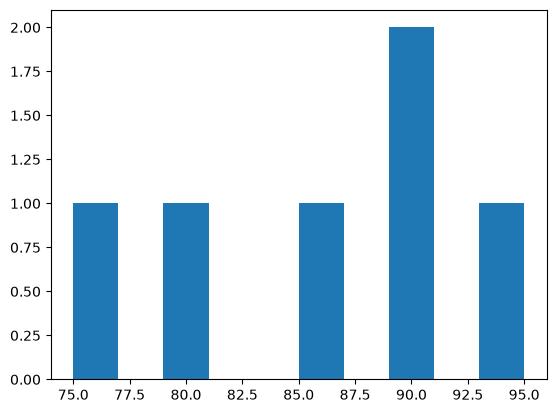

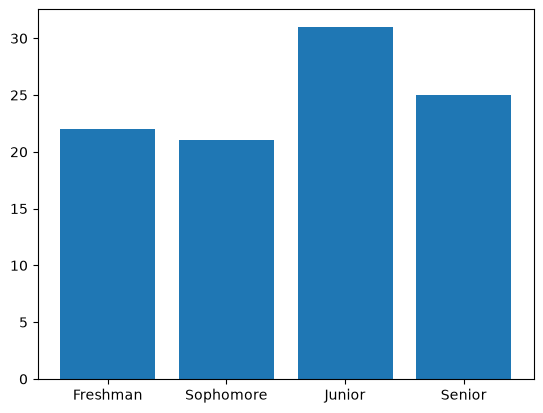

In [11]:
scores = [75, 80, 85, 90, 90, 95]
make_plot(scores)

classes = ['Freshman', 'Sophomore', 'Junior', 'Senior']
num_students = [22, 21, 31, 25]
make_plot(classes, num_students)

**Check your understanding:** Why does one argument create a histogram, while two create a bar chart? What happens with `make_plot()` and no arguments?

### `*args` in a familiar function: `print()`

Run `help(print)` and look at its signature. The positional values are collected in `*args`.

In [12]:
help(print)

Help on built-in function print in module builtins:

print(*args, sep=' ', end='\n', file=None, flush=False)
    Prints the values to a stream, or to sys.stdout by default.

    sep
      string inserted between values, default a space.
    end
      string appended after the last value, default a newline.
    file
      a file-like object (stream); defaults to the current sys.stdout.
    flush
      whether to forcibly flush the stream.



### Run and Compare

Run the cell. What is the difference between `sep='*'` and passing `'*'` as an additional positional argument? The first changes how items are separated; the second becomes one of the items.

In [13]:
print('score:', 95, 'passed:', True, sep="*")
print('score:', 95, 'passed:', True, '*')

score:*95*passed:*True
score: 95 passed: True *


### Exercise 6

Print the following string to the screen: "Port-au-Prince, Haiti". The catch: you can only explicitly type the hyphen character `-` **once**.


In [14]:
print('Port', 'au', 'Prince, Haiti', sep='-')

Port-au-Prince, Haiti


## 3. `**kwargs`

`**kwargs` allows a function to receive a variable number of **keyword arguments**.

### Exercise 7

Run the code below and answer the following questions based on the output:

1. What type is `kwargs`?
2. What becomes the dictionary keys?
3. What happens when no keyword arguments are passed?


In [15]:
def show_kwargs(**kwargs):
    print('kwargs:', kwargs)
    print('type:', type(kwargs))
    print('length:', len(kwargs))
    print('keys:', kwargs.keys())
    print('values:', kwargs.values())
    print()

show_kwargs(name='Annie', major='Data Science')
show_kwargs(sport='football', town='Decatur', number=5)
show_kwargs()


kwargs: {'name': 'Annie', 'major': 'Data Science'}
type: <class 'dict'>
length: 2
keys: dict_keys(['name', 'major'])
values: dict_values(['Annie', 'Data Science'])

kwargs: {'sport': 'football', 'town': 'Decatur', 'number': 5}
type: <class 'dict'>
length: 3
keys: dict_keys(['sport', 'town', 'number'])
values: dict_values(['football', 'Decatur', 5])

kwargs: {}
type: <class 'dict'>
length: 0
keys: dict_keys([])
values: dict_values([])



### Example: Reading values from `kwargs`

A function can look for specific keys and ignore others. Run each example below separately to see which values the function uses.

Because `kwargs` is a dictionary, we can check for a key and access its value.

In [16]:
def student_info(**kwargs):
    if 'name' in kwargs:
        print(f"Name: {kwargs['name']}")
    if 'major' in kwargs:
        print(f"Major: {kwargs['major']}")

student_info(name='Annie', major='Data Science')



Name: Annie
Major: Data Science


**Example 2 — An unused keyword:** The function only looks for `name` and `major`. Run the next cell and notice that `age` is accepted but not printed.

In [17]:
student_info(name='Annie', age=22)

Name: Annie


**Example 3 — More custom keywords:** We add the keywords `favorite_movie` and `favorite_food`. These are accepted into the dictionary, but this function does not use them. Not every library function silently accepts arbitrary keywords.

In [18]:
student_info(name='Annie', major='Data Science', favorite_movie="Gone With the Wind", favorite_food = "Garlic Bread")

Name: Annie
Major: Data Science


### Exercise: Combine two keyword values

Modify `student_info()` to print one of the following single sentences, where "___" should be replaced with an appropriate sequence of characters.

- If both `name` and `major` are included, it should print the string `Hi, I'm ___ and I'm majoring in ___!`

- If only `name` is included, it should print the string `Hi, I'm ___!`

- If `name` is **not** included, it should simply print the string `Hi!`



In [19]:
def student_info(**kwargs):
    if 'name' in kwargs:
        if 'major' in kwargs:
            print(f"Hi, I'm {kwargs['name']} and I'm majoring in {kwargs['major']}!")
        else:
            print(f"Hi, I'm {kwargs['name']}!")
    else:
        print("Hi!")

student_info(name='Annie')
student_info(name='Annie', major='Data Science')
student_info(major = 'Data Science')

Hi, I'm Annie!
Hi, I'm Annie and I'm majoring in Data Science!
Hi!


### Exercise 8: Optional Plot Settings with `**kwargs`

Suppose we want to create a plotting function that always receives the same data, but we want to allow optional settings such as `color` or whether to show a grid.

Complete `make_bar_plot()` so that:
- If `'color'` is in `kwargs`, use its value to set the color of the bars.
- If `'grid'` is in `kwargs` and its value is `True`, display a grid using `plt.grid()`.

In [20]:
def make_bar_plot(categories, height, **kwargs):
    if 'color' in kwargs:
        plt.bar(categories, height, color=kwargs['color'])
    else:
        plt.bar(categories, height)

    if 'grid' in kwargs:
        if kwargs['grid']:
            plt.grid()

    plt.show()

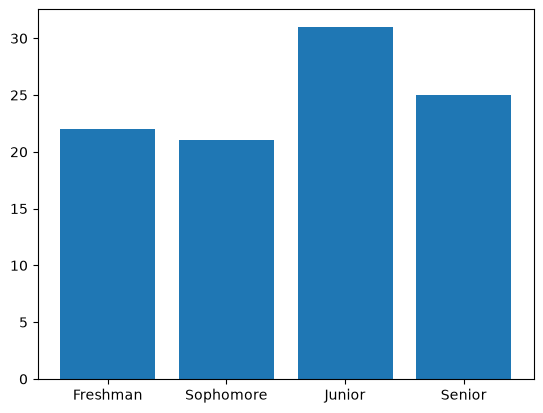

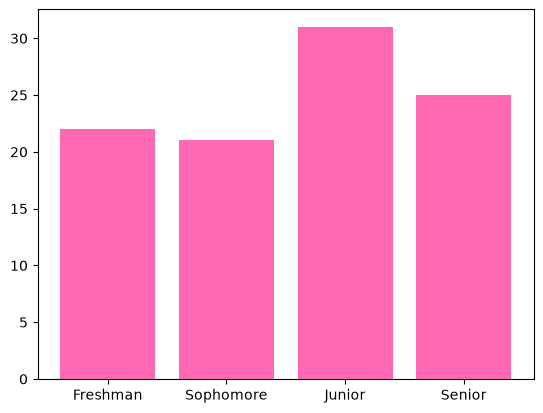

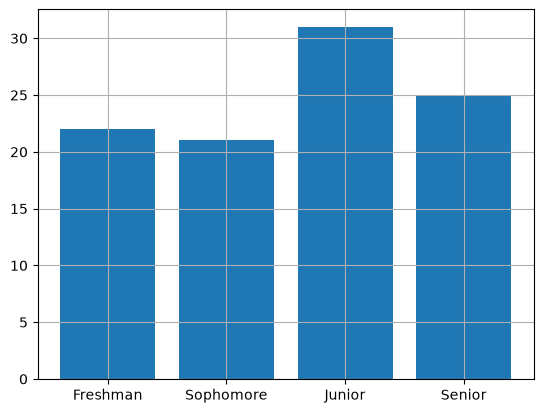

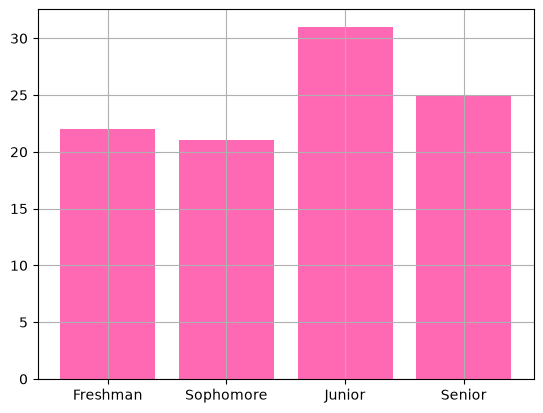

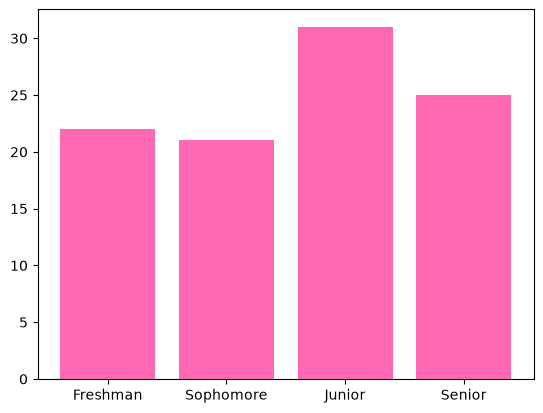

In [21]:
classes = ['Freshman', 'Sophomore', 'Junior', 'Senior']
num_students = [22, 21, 31, 25]

# Run some test cases:
make_bar_plot(classes, num_students)
make_bar_plot(classes, num_students, color='hotpink')
make_bar_plot(classes, num_students, grid=True)
make_bar_plot(classes, num_students, color='hotpink', grid=True)
make_bar_plot(classes, num_students, color='hotpink', grid=False)

### FYI: The names `kwargs` and `args` are just a convention

The `**` matters, not the variable name. The function below works with `**blah`, although `**kwargs` is the usual and more clear convention.

In [22]:
def student_info(**blah):
    if 'name' in blah:
        print(f"Name: {blah['name']}")
    if 'major' in blah:
        print(f"Major: {blah['major']}")

student_info(name='Annie', major='Data Science')

Name: Annie
Major: Data Science


Similarly, `*blah` collects positional arguments into a tuple, but `*args` is the usual name.

In [23]:
def show_args(*blah):
    print('args:', blah)
    print('type:', type(blah))
    print('length:', len(blah))
    print()

show_args(2, 4)
show_args('hello', [1, 2, 3], 6)
show_args()

args: (2, 4)
type: <class 'tuple'>
length: 2

args: ('hello', [1, 2, 3], 6)
type: <class 'tuple'>
length: 3

args: ()
type: <class 'tuple'>
length: 0



### Final Check

For each function below, identify whether it demonstrates `*`, `*args`, or `**kwargs`.

```python
def f1(*, x, y):
    ...

def f2(*values):
    ...

def f3(**options):
    ...
```
